# Lab 04 — Bài toán 2: Hồi quy Logistic (Diabetes)

**Chạy trên VS Code:** Chọn Python kernel của `ml_lab_env` rồi **Run All**. Quy trình: stratified split → bù khuyết các số 0 bất hợp lý bằng median Train → StandardScaler Train → Logistic Regression L2 → Confusion Matrix / ROC-AUC → threshold tuning.

## 1. Đọc dữ liệu, quan sát các số 0 không hợp lệ

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)

df = pd.read_csv(Path('../data/raw/diabetes.csv'))
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print('Kích thước:', df.shape)
print('Phân bố Outcome:\n', df['Outcome'].value_counts())
print('Số 0 bất hợp lý:\n', (df[zero_cols] == 0).sum())
display(df.head())

Kích thước: (768, 9)
Phân bố Outcome:
 Outcome
0    500
1    268
Name: count, dtype: int64
Số 0 bất hợp lý:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Chia theo tỷ lệ nhãn bằng `stratify=y`

In [5]:
X = df.drop(columns=['Outcome'])
y = df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train = X_train.copy()
X_test = X_test.copy()
print('Train/Test:', len(X_train), len(X_test))
print('Tỷ lệ bệnh Train/Test:', y_train.mean().round(4), y_test.mean().round(4))

Train/Test: 614 154
Tỷ lệ bệnh Train/Test: 0.3485 0.3506


## 3. Bù giá trị 0 bằng median chỉ tính từ Train

Các giá trị 0 trong `Pregnancies` là hợp lệ nên **không thay** cột này.

In [6]:
train_medians = {}
for col in zero_cols:
    train_medians[col] = X_train.loc[X_train[col] != 0, col].median()
    X_train[col] = X_train[col].replace(0, train_medians[col])
    X_test[col] = X_test[col].replace(0, train_medians[col])
print('Median từ Train:', train_medians)
print('Số 0 còn lại ở các cột y sinh trên Train:', (X_train[zero_cols] == 0).sum().sum())
print('Số 0 còn lại ở các cột y sinh trên Test:', (X_test[zero_cols] == 0).sum().sum())

Median từ Train: {'Glucose': np.float64(117.0), 'BloodPressure': np.float64(72.0), 'SkinThickness': np.float64(29.0), 'Insulin': np.float64(125.0), 'BMI': np.float64(32.4)}
Số 0 còn lại ở các cột y sinh trên Train: 0
Số 0 còn lại ở các cột y sinh trên Test: 0


## 4. Chuẩn hóa train-only, huấn luyện Logistic Regression với L2 (mặc định)

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
y_proba = model.predict_proba(X_test_scaled)[:, 1]
y_pred = model.predict(X_test_scaled)
print('Đã hội tụ sau:', int(model.n_iter_[0]), 'lần lặp')

Đã hội tụ sau: 8 lần lặp


## 5. Confusion Matrix, Precision, Recall, F1 và ROC-AUC

Confusion matrix:
 [[82 18]
 [27 27]]
              precision    recall  f1-score   support

Lớp 0 (Khỏe)       0.75      0.82      0.78       100
Lớp 1 (Bệnh)       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154

ROC-AUC = 0.813


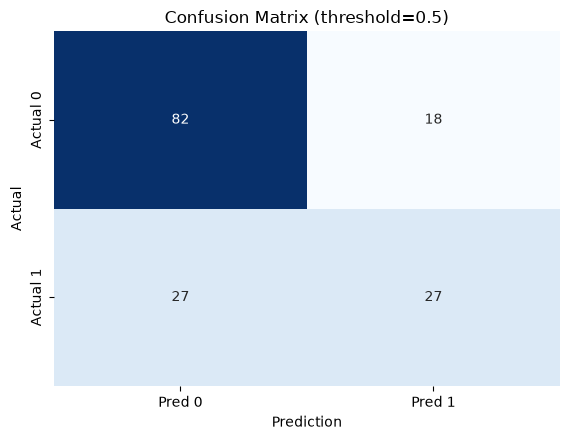

In [8]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print('Confusion matrix:\n', cm)
print(classification_report(y_test, y_pred, target_names=['Lớp 0 (Khỏe)', 'Lớp 1 (Bệnh)']))
print('ROC-AUC =', round(roc_auc_score(y_test, y_proba), 4))
fig, ax = plt.subplots(figsize=(5.8, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'],
            yticklabels=['Actual 0', 'Actual 1'], cbar=False, ax=ax)
ax.set(title='Confusion Matrix (threshold=0.5)', xlabel='Prediction', ylabel='Actual')
plt.tight_layout()
plt.show()

## 6. Đường cong ROC

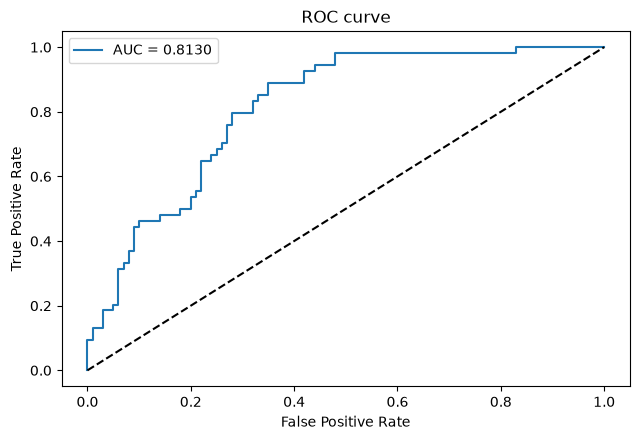

In [9]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(fpr, tpr, label=f'AUC = {auc:.4f}')
ax.plot([0, 1], [0, 1], 'k--')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC curve')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Thực nghiệm ngưỡng 0.3; 0.4; 0.5; 0.6

**Chú ý:** Bảng trên tập Test nhằm minh họa. Trong ứng dụng thật, phải chọn ngưỡng trên tập Validation hoặc cross-validation rồi mới đánh giá một lần trên Test.

,Threshold,TN,FP,FN,TP,Precision,Recall,F1
0,0.3,71,29,11,43,0.5972,0.7963,0.6825
1,0.4,78,22,19,35,0.6140,0.6481,0.6306
2,0.5,82,18,27,27,0.6000,0.5000,0.5455
3,0.6,86,14,29,25,0.6410,0.4630,0.5376


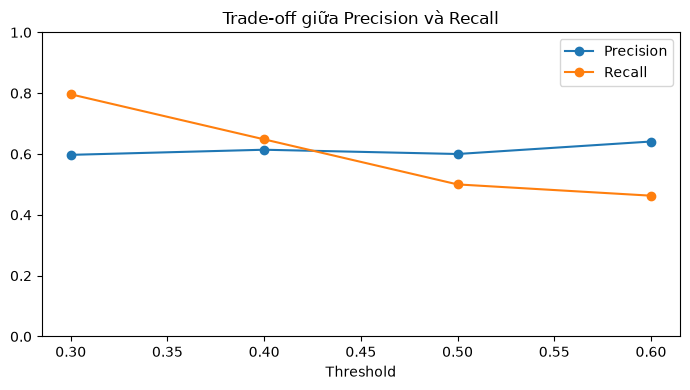

In [10]:
rows = []
for th in [0.3, 0.4, 0.5, 0.6]:
    candidate = (y_proba >= th).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, candidate, labels=[0, 1]).ravel()
    rows.append({'Threshold': th, 'TN': tn_, 'FP': fp_, 'FN': fn_, 'TP': tp_,
                 'Precision': precision_score(y_test, candidate, zero_division=0),
                 'Recall': recall_score(y_test, candidate, zero_division=0),
                 'F1': f1_score(y_test, candidate, zero_division=0)})
threshold_table = pd.DataFrame(rows)
display(threshold_table.round(4))
threshold_table.plot(x='Threshold', y=['Precision', 'Recall'], marker='o', figsize=(7, 4))
plt.ylim(0, 1)
plt.title('Trade-off giữa Precision và Recall')
plt.tight_layout()
plt.show()

## 8. Tác động của siêu tham số C

Trong `LogisticRegression`, tham số C là nghịch đảo của độ mạnh điều chuẩn L2. Giảm C làm co trọng số, tăng C cho trọng số lớn hơn. Đây chỉ là so sánh mô tả, **không dùng Test để chọn C**.

In [11]:
comparisons = []
for C in [0.01, 0.1, 1.0, 10.0, 100.0]:
    candidate = LogisticRegression(C=C, solver='lbfgs', max_iter=1000, random_state=42)
    candidate.fit(X_train_scaled, y_train)
    comparisons.append({'C': C, 'L2 norm(coef)': np.linalg.norm(candidate.coef_),
                        'Train AUC': roc_auc_score(y_train, candidate.predict_proba(X_train_scaled)[:, 1]),
                        'Test AUC': roc_auc_score(y_test, candidate.predict_proba(X_test_scaled)[:, 1])})
display(pd.DataFrame(comparisons).round(4))

,C,L2 norm(coef),Train AUC,Test AUC
0,0.01,0.6832,0.8465,0.7985
1,0.10,1.2458,0.8509,0.8104
2,1.00,1.4486,0.8502,0.8130
3,10.00,1.4765,0.8500,0.8130
4,100.00,1.4794,0.8500,0.8131
